# Proton/helium
Simulated protons against simulated helium: Hillas parameters with the same selection, and reconstructed directions and
shower cores, from two already processed sim_telarray productions (run `process_sims.ipynb` on each first).

Everything is set in **Selection** below: pick a config per production, then override its telescopes or selection there to
compare selections. The histograms and profiles are made by the functions in **Plotting**.

Camera coordinates are sim_telarray's, fixed to the alt-az mount: +x towards higher altitude, +y towards lower azimuth.
`distance` and `alpha` are from the camera center (`process_simulation()`'s default `x`, `y`): the source position for
a point-like gamma production without a wobble.

# Imports

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import LogNorm

from heap import events as ev
from heap.config import local_simulation
from heap import process_simulation as ps
from heap.reconstruction import core_distances, reconstruct_cores, reconstruct_directions, tilted_frame, tilted_positions
from simulation_tools.run_simulation import load_config

# Selection

In [2]:
# one simulation config per production: configs/local.yaml's, or any other, e.g. Path("~/panoseti/simulations/<name>.yaml")
PROTON_CONFIG = local_simulation("proton")
HELIUM_CONFIG = local_simulation("helium")
SAMPLES = {"proton": load_config(PROTON_CONFIG), "helium": load_config(HELIUM_CONFIG)}

# the spectral index each production is weighted to (dN/dE ~ E^index), None = as simulated;
# e.g. -2.7 for cosmic-ray protons, about -2.6 for cosmic-ray helium
SPECTRAL_INDEX = {"proton": None, "helium": None}

# override any of these, e.g. TELESCOPES = ["T1", "T2", "T3"] or IMAGE_CUTS = {"width": ("value", 0.3)}
TELESCOPES = None # None = every telescope; "T<sim_telarray id>"
MIN_TEL = 2
MIN_NPIX = 3
MAX_DISTANCE = 2 # deg, images farther from the camera center are removed
IMAGE_CUTS = {"distance": ("value", MAX_DISTANCE)} # {column: (mode, threshold)}, see heap.events.apply_cut(); "nsigma" thresholds are per production

# theta2's source (deg, camera coordinates): the camera center, a point-like gamma production's source without a wobble
SOURCE_X, SOURCE_Y = 0, 0

# plotting
ENERGY_BINS = np.logspace(0, 3.6, 19) # TeV, on the simulated histogram's bin edges (every 0.05 in log10)
COLORS = {"proton": "C3", "helium": "C2"}

# Plotting

In [3]:
# column: (axis label, bin edges)
HILLAS_PARAMS = {
    "N_pix": ("N_pix", np.arange(0.5, 81.5, 2)),
    "log10_size": ("log10 size (ADC)", np.linspace(1, 6, 51)),
    "length": ("length (deg)", np.linspace(0, 2, 51)),
    "width": ("width (deg)", np.linspace(0, 1, 51)),
    "length_width": ("length / width", np.linspace(1, 10, 46)),
    "length_log10_size": ("length / log10 size (deg)", np.linspace(0, 1, 51)),
    "distance": ("distance (deg)", np.linspace(0, 7, 36)),
    "alpha": ("alpha (deg)", np.linspace(0, 90, 31)),
    "miss": ("miss (deg)", np.linspace(0, 3, 31)),
}
EVENT_PARAMS = { # see event_parameters()
    "n_images": ("images per event", np.arange(0.5, 8.5)),
    "log10_total_size": ("log10 total size (ADC)", np.linspace(1, 6, 41)),
    "log10_SizeSecondMax": ("log10 second largest size (ADC)", np.linspace(1, 6, 41)),
    "max_distance": ("max distance (deg)", np.linspace(0, 7, 36)),
    "theta2": ("theta^2 (deg^2)", np.linspace(0, 4, 41)),
}

def legend_and_title(fig, ax, n_panels, title):
    """the suptitle and ax's legend, shared below the suptitle if there are several panels"""
    if n_panels > 1:
        # constrained layout puts an outside legend over the suptitle, so the legend's title stands in for it
        handles, labels = ax.get_legend_handles_labels()
        fig.legend(handles, labels, loc="outside upper center", ncols=len(labels), fontsize=8, frameon=False,
                   title=title, title_fontsize="large")
    else:
        ax.legend(fontsize=8)
        fig.suptitle(title)

def plot_hists(samples, params, title, n_cols=4):
    """each sample's normalized, weighted histogram, one panel per column of params"""
    n_rows = int(np.ceil(len(params) / n_cols))
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(4.2*n_cols, 3.6*n_rows), squeeze=False, layout="constrained")
    for ax, (column, (label, bins)) in zip(axs.flat, params.items()):
        for name, sample in samples.items():
            s = sample.dropna(subset=[column])
            ax.hist(s[column], bins, weights=s.weight, density=True, histtype="step", color=COLORS[name], label=f"{name} N={len(s)}")
        ax.set(xlabel=label, ylabel="normalized counts")
    legend_and_title(fig, axs.flat[0], len(params), title)
    for ax in axs.flat[len(params):]:
        ax.axis("off")
    plt.show()

def plot_profiles(samples, profiles, title, n_cols=4, min_entries=10):
    """each sample's weighted mean of y in bins of x, with its error, one panel per (x, y, x bin edges) in profiles"""
    n_rows = int(np.ceil(len(profiles) / n_cols))
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(4.2*n_cols, 3.6*n_rows), squeeze=False, layout="constrained")
    for ax, (x, y, bins) in zip(axs.flat, profiles):
        centers = (bins[1:] + bins[:-1]) / 2
        for name, sample in samples.items():
            s = sample.dropna(subset=[x, y])
            n, _ = np.histogram(s[x], bins)
            sw, _ = np.histogram(s[x], bins, weights=s.weight)
            with np.errstate(divide="ignore", invalid="ignore"):
                mean = np.histogram(s[x], bins, weights=s.weight * s[y])[0] / sw
                std = np.sqrt(np.clip(np.histogram(s[x], bins, weights=s.weight * s[y]**2)[0] / sw - mean**2, 0, None))
            ok = n >= min_entries
            ax.errorbar(centers[ok], mean[ok], yerr=std[ok] / np.sqrt(n[ok]), fmt="o-", ms=3, color=COLORS[name], label=name)
        ax.set(xlabel=x, ylabel=f"mean {y}")
    legend_and_title(fig, axs.flat[0], len(profiles), title)
    for ax in axs.flat[len(profiles):]:
        ax.axis("off")
    plt.show()

In [4]:
runs, images, showers = {}, {}, {}
for label, cfg in SAMPLES.items():
    runs[label], images[label], showers[label] = ps.load_production(cfg, TELESCOPES)
    header = runs[label].iloc[0]
    # each shower's weight from the simulated power law to SPECTRAL_INDEX, mean 1
    weight = showers[label].energy ** ((SPECTRAL_INDEX[label] or header.spectral_index) - header.spectral_index)
    showers[label]["weight"] = weight / weight.mean()
    print(f"{label}: {cfg['production']['name']} ({cfg['sim_telarray']['tag']}), {len(runs[label])} runs, "
          f"{(runs[label].n_showers * runs[label].n_use).sum()} events simulated")
    print(f"    {header.energy_range[0]:g}-{header.energy_range[1]:g} TeV, index {header.spectral_index:.2g} weighted to "
          f"{SPECTRAL_INDEX[label]}, cores within {header.core_range[1]:g} m, viewcone {header.viewcone[0]:g}-{header.viewcone[1]:g} deg, "
          f"pointing alt {runs[label].alt.mean():.2f}, az {runs[label].az.mean():.2f} deg")
if TELESCOPES is None:
    TELESCOPES = sorted(set().union(*(images[label].Telescope for label in SAMPLES)))
SELECTED = BASE_SELECTED = f"≥{MIN_TEL} images per event, ≥{MIN_NPIX} pixels per image" + (f", {IMAGE_CUTS}" if IMAGE_CUTS else "")
print(f"telescopes {TELESCOPES}, selected events: {SELECTED} (and the additional cuts below)")

proton: proton_diffuse (v2), 1000 runs, 4000000 events simulated
    6-2000 TeV, index -2.7 weighted to None, cores within 500 m, viewcone 0-8 deg, pointing alt 70.00, az 191.03 deg
helium: helium_diffuse (v2), 1000 runs, 4000000 events simulated
    6-2000 TeV, index -2.7 weighted to None, cores within 500 m, viewcone 0-8 deg, pointing alt 70.00, az 191.03 deg
telescopes ['T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7'], selected events: ≥2 images per event, ≥3 pixels per image, {'distance': ('value', 2)} (and the additional cuts below)


In [5]:
# both productions should be cleaned the same way
pd.DataFrame({
    label: json.loads((ps.processed_path(cfg) / f"{cfg['production']['name']}_processing.json").read_text())
    for label, cfg in SAMPLES.items()
})

,proton,helium
nsig,5.0,5.0
fit_gaussian,True,True
x,None,None
y,None,None
image_threshold,4.0,4.0
border_threshold,2.0,2.0
keep_brightest_island,True,True


# Events
Each production's images matched into array events by `Run` and `EventID` (`heap.process_simulation.load_events()`),
with their shower's spectral weight and energy, then the selection (`heap.events.apply_cuts()`): at least `MIN_TEL` images per event, `MIN_NPIX` pixels per image, and any `IMAGE_CUTS`. Then each selected event's shower core, from the telescopes' positions in
the plane perpendicular to the pointing (`heap.reconstruction.reconstruct_cores()`), and each image's reconstructed
impact distance (`impact_reco`).

In [6]:
arrays, cores = {}, {}
for label in SAMPLES:
    imgs = images[label].merge(showers[label][["Event", "weight", "energy"]], on="Event")
    imgs["log10_size"] = np.log10(imgs["size"].where(imgs["size"] > 0))
    imgs["length_width"] = imgs.length / imgs.width
    imgs["length_log10_size"] = imgs.length / imgs.log10_size
    imgs["log10_energy"] = np.log10(imgs.energy)
    images[label] = imgs
    arrays[label] = ev.apply_cuts(imgs, min_tel=MIN_TEL, min_npix=MIN_NPIX, telescopes=TELESCOPES, cuts=IMAGE_CUTS)
    header, alt, az = runs[label].iloc[0], runs[label].alt.mean(), runs[label].az.mean()
    positions = tilted_positions(arrays[label], {f"T{tel_id}": pos for tel_id, pos in zip(header.tel_id, header.tel_pos)}, *tilted_frame(alt, az))
    cores[label] = reconstruct_cores(arrays[label], positions)
    arrays[label]["impact_reco"] = core_distances(arrays[label], positions, cores[label])
    print(f"{label}: {imgs.Event.nunique()} events ({len(imgs)} images) in all, "
          f"{arrays[label].Event.nunique()} events ({len(arrays[label])} images) selected")

proton: 259076 events (313350 images) in all, 3151 events (6773 images) selected
helium: 173928 events (215457 images) in all, 2478 events (5415 images) selected


## Additional cuts
Image cuts on the selected images, after the selection above; each event then needs `MIN_TEL` images left. Cores and
`impact_reco` stay as reconstructed in the selection. Everything below uses the images passing them; rerun the cell above
before loosening them.

In [7]:
# pandas queries on the images' columns, e.g. "length / log10_size > 0.2", "width < 0.3", "Telescope != 'T4'"; [] = none
ADDITIONAL_CUTS = []

for label, array in arrays.items():
    for cut in ADDITIONAL_CUTS:
        array = array.query(cut)
    arrays[label] = array[array.groupby("Event").Event.transform("size") >= MIN_TEL]
    print(f"{label}: {arrays[label].Event.nunique()} events ({len(arrays[label])} images) pass")
SELECTED = ", ".join([BASE_SELECTED, *ADDITIONAL_CUTS])
print(f"selected events: {SELECTED}")

proton: 3151 events (6773 images) pass
helium: 2478 events (5415 images) pass
selected events: ≥2 images per event, ≥3 pixels per image, {'distance': ('value', 2)}


## Energy
Each production's simulated, triggered and kept events and effective area (unweighted, see
`heap.process_simulation.plot_energies()`).

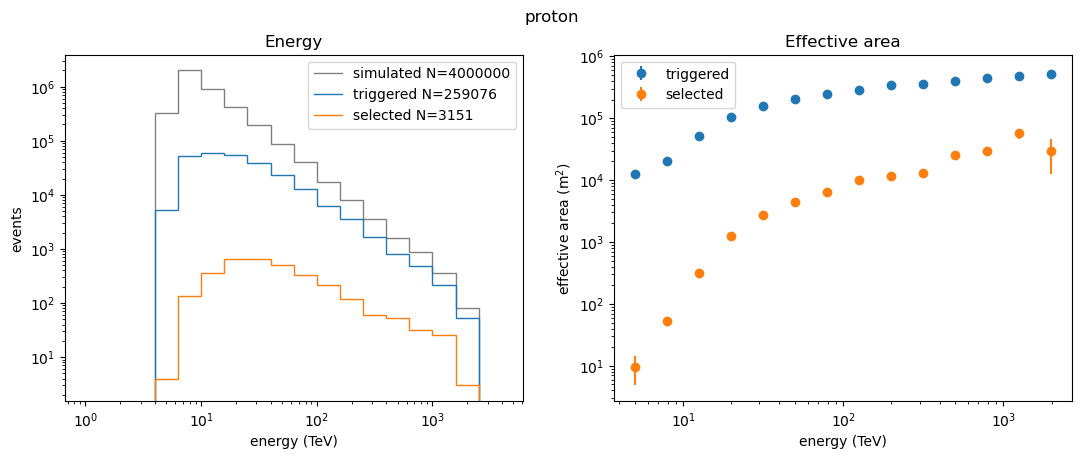

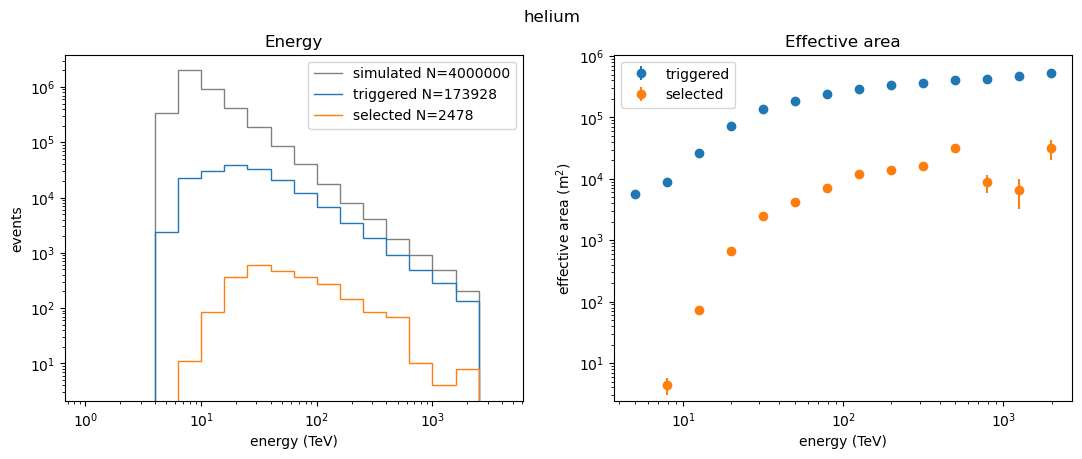

In [8]:
for label in SAMPLES:
    triggered = showers[label][showers[label].Event.isin(images[label].Event)]
    selected = showers[label][showers[label].Event.isin(arrays[label].Event)]
    fig = ps.plot_energies(runs[label], {"triggered": triggered, "selected": selected}, ENERGY_BINS)
    fig.suptitle(label)
    plt.show()

# Hillas parameters
Normalized histograms of every image, weighted by its shower's spectral weight.

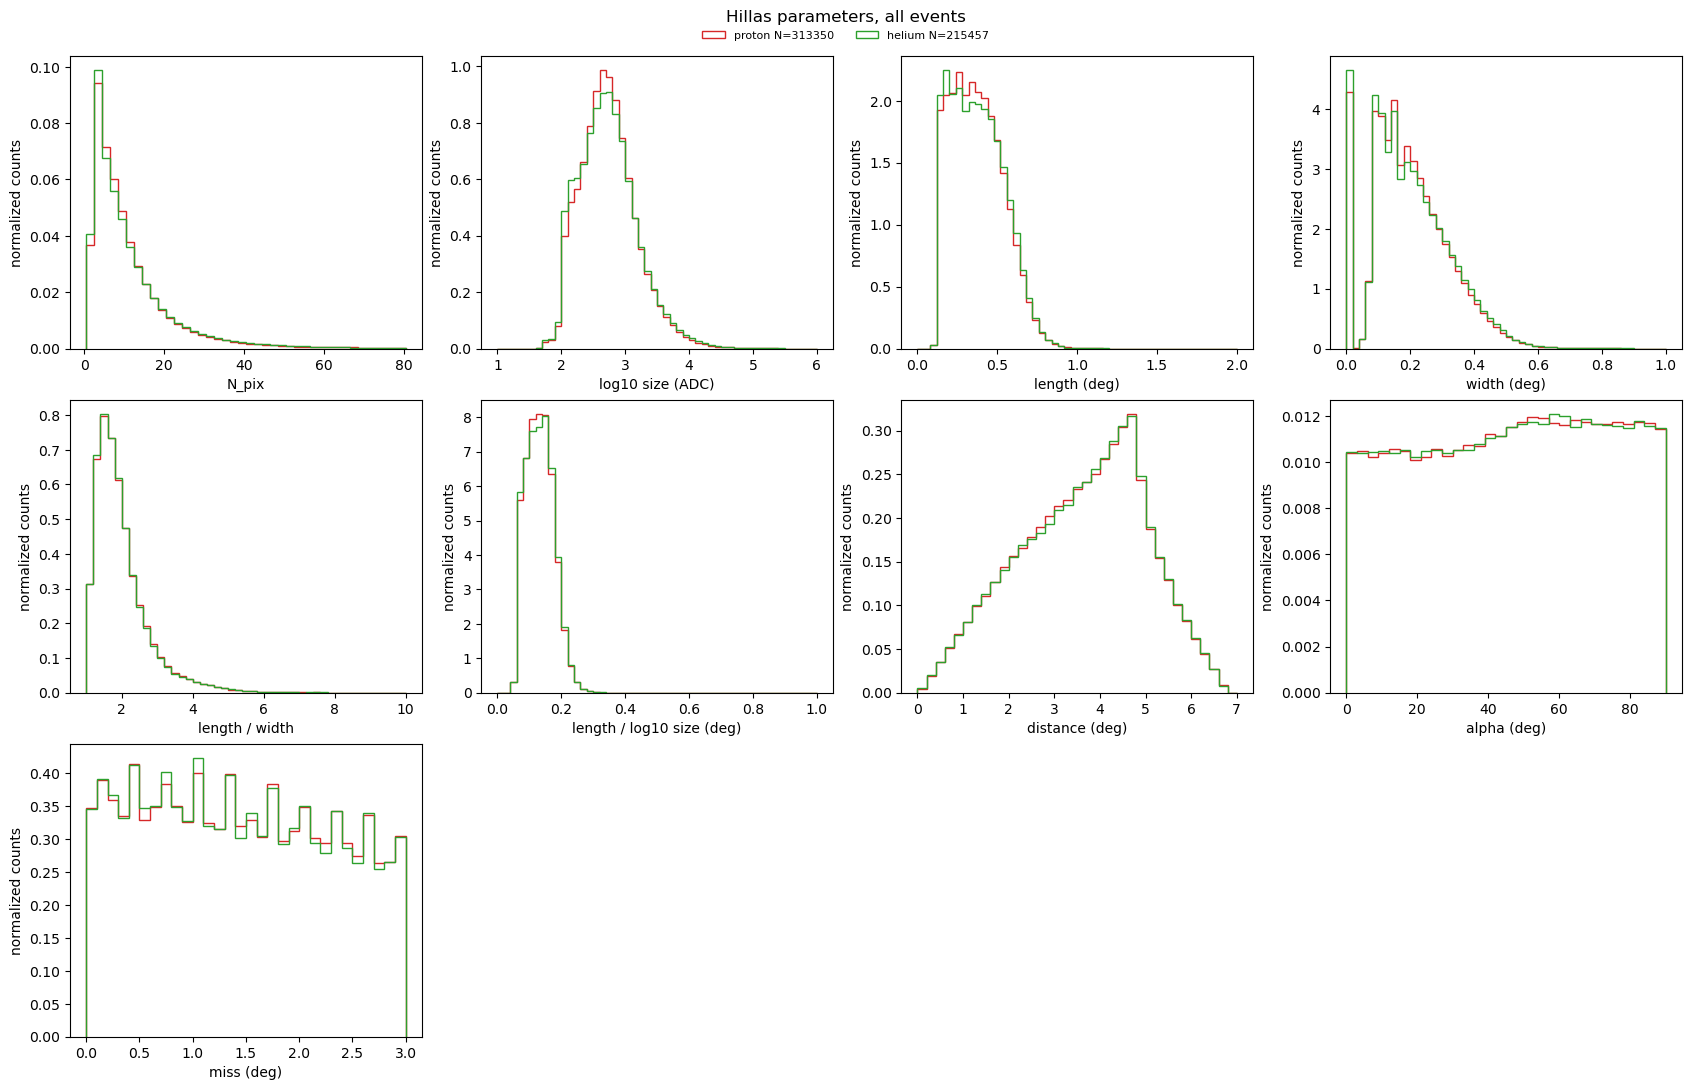

In [9]:
plot_hists(images, HILLAS_PARAMS, "Hillas parameters, all events")

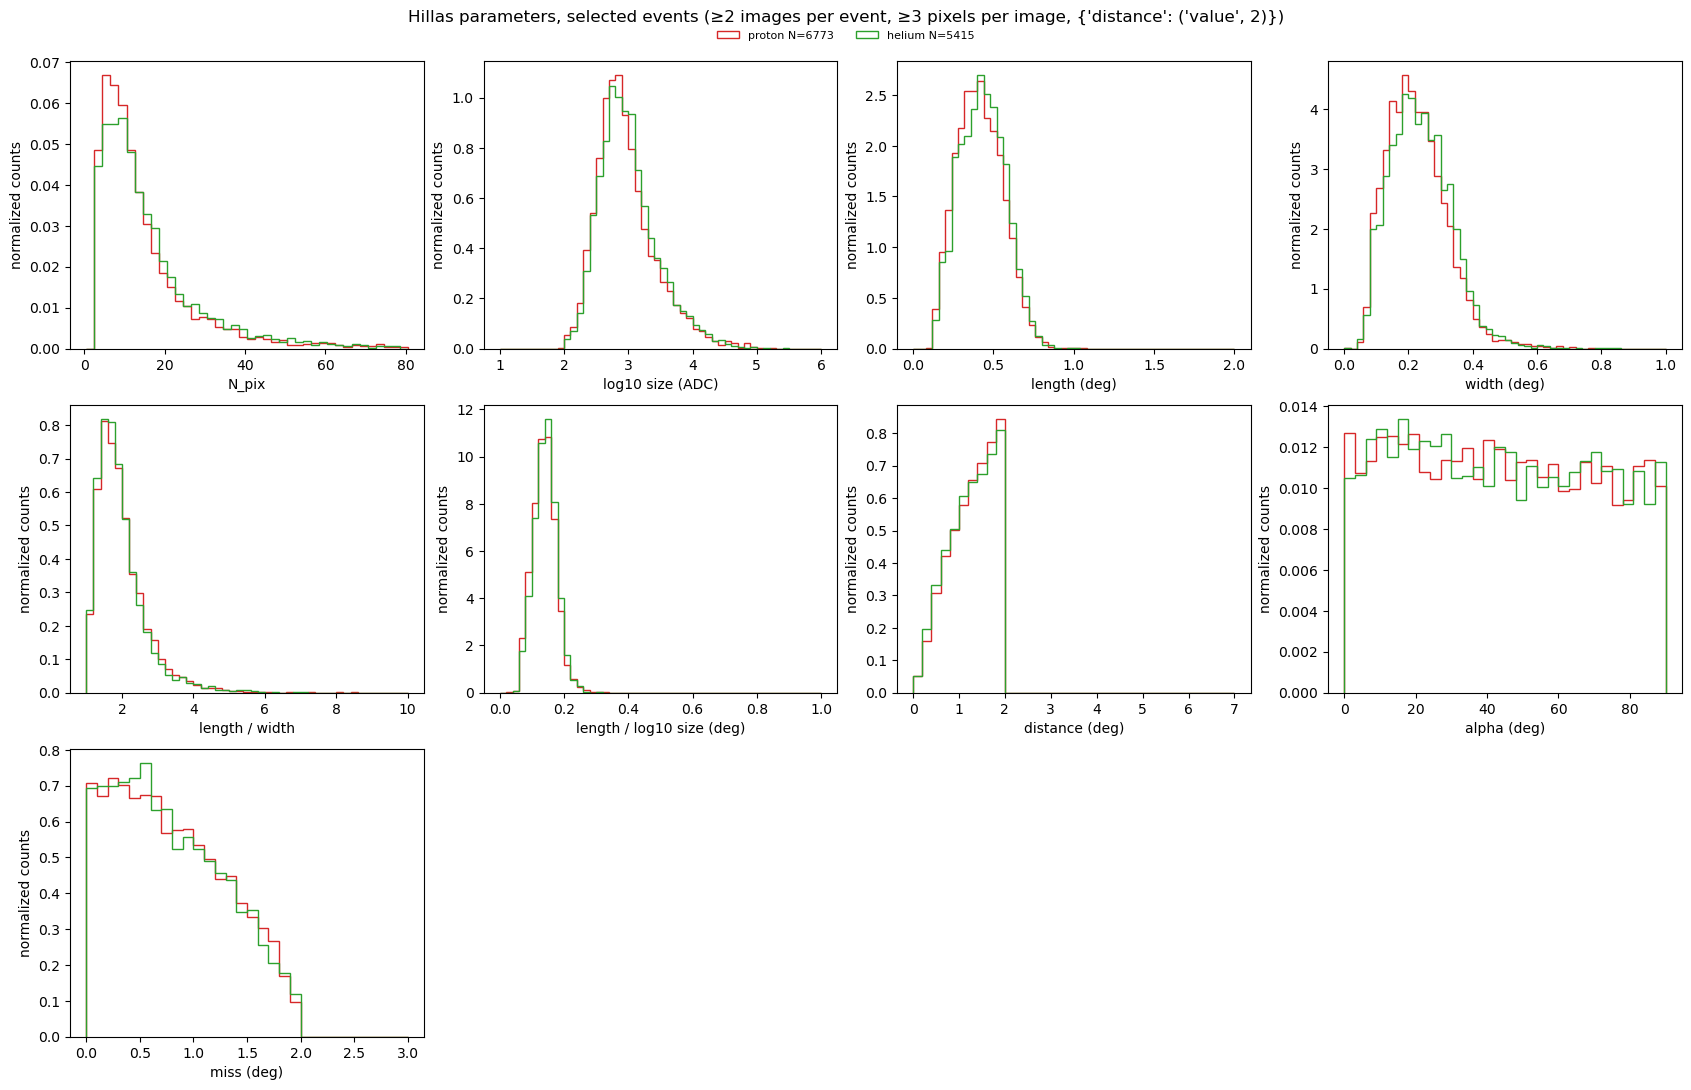

In [10]:
plot_hists(arrays, HILLAS_PARAMS, f"Hillas parameters, selected events ({SELECTED})")

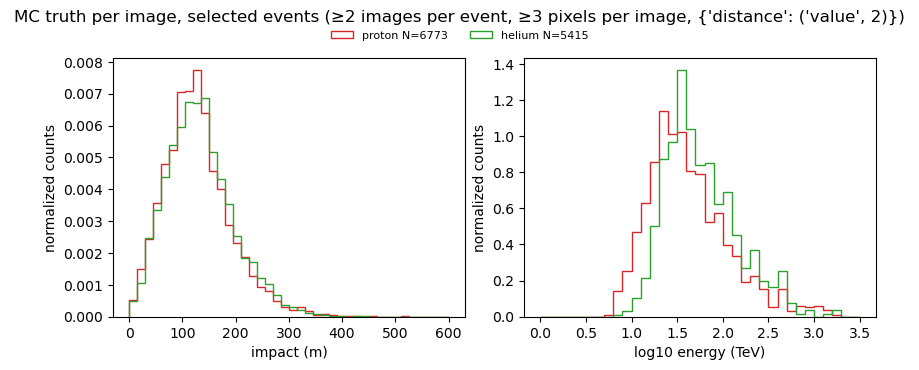

In [11]:
plot_hists(arrays, {
    "impact": ("impact (m)", np.linspace(0, 600, 41)),
    "log10_energy": ("log10 energy (TeV)", np.linspace(0, 3.5, 36)),
}, f"MC truth per image, selected events ({SELECTED})", n_cols=2)

In [12]:
pd.concat({label: array[["N_pix", "size", "length", "width", "length_width", "distance", "alpha", "impact_reco"]].describe() for label, array in arrays.items()}, axis=1)

proton                                                          \
             N_pix           size       length         width  length_width   
count  6773.000000    6773.000000  6773.000000  6.773000e+03  6.773000e+03   
mean     15.994685    2146.065128     0.416257  2.257276e-01  1.694063e+04   
std      16.523998    6228.155628     0.141115  9.283507e-02  1.394020e+06   
min       3.000000      91.889061     0.082998  2.634178e-09  1.011541e+00   
25%       7.000000     449.640559     0.310060  1.556523e-01  1.503258e+00   
50%      11.000000     768.027773     0.407750  2.151083e-01  1.826254e+00   
75%      18.000000    1566.985564     0.516064  2.809206e-01  2.283458e+00   
max     212.000000  160418.816292     1.047557  7.780413e-01  1.147254e+08   

                                                    helium                 \
          distance        alpha   impact_reco        N_pix           size   
count  6773.000000  6773.000000   6773.000000  5415.000000    5415.000000   
mean      1.287377    43.671262    345.990711    17.103416    2168.796816   
std       0.478600    25.961560   2022.903254    17.073864    6468.439749   
min       0.012738     0.007385      0.013817     3.000000     103.464207   
25%       0.930128    20.670556     92.360370     7.000000     490.988631   
50%       1.350549    42.837558    147.465761    12.000000     871.297771   
75%       1.695527    66.046940    219.429426    20.000000    1746.221522   
max       1.999994    89.991110  70889.808878   316.000000  264483.333215   

                                                                          \
            length         width  length_width     distance        alpha   
count  5415.000000  5.415000e+03  5.415000e+03  5415.000000  5415.000000   
mean      0.432003  2.385902e-01  1.846114e+04     1.263591    43.822075   
std       0.139990  9.554505e-02  1.358350e+06     0.485527    25.934532   
min       0.125107  3.725290e-09  1.003313e+00     0.053471     0.070544   
25%       0.325175  1.695707e-01  1.496597e+00     0.897504    21.022503   
50%       0.430766  2.308421e-01  1.794528e+00     1.315513    43.154753   
75%       0.530755  2.987501e-01  2.210120e+00     1.679170    66.467455   
max       1.024852  8.403473e-01  9.995647e+07     1.999977    89.964475   

                      
         impact_reco  
count    5413.000000  
mean      470.062977  
std      6512.390436  
min         0.183154  
25%        95.258810  
50%       153.261713  
75%       221.933904  
max    276418.666703

## Profiles
Mean of one parameter in bins of another for the selected events, with its error.

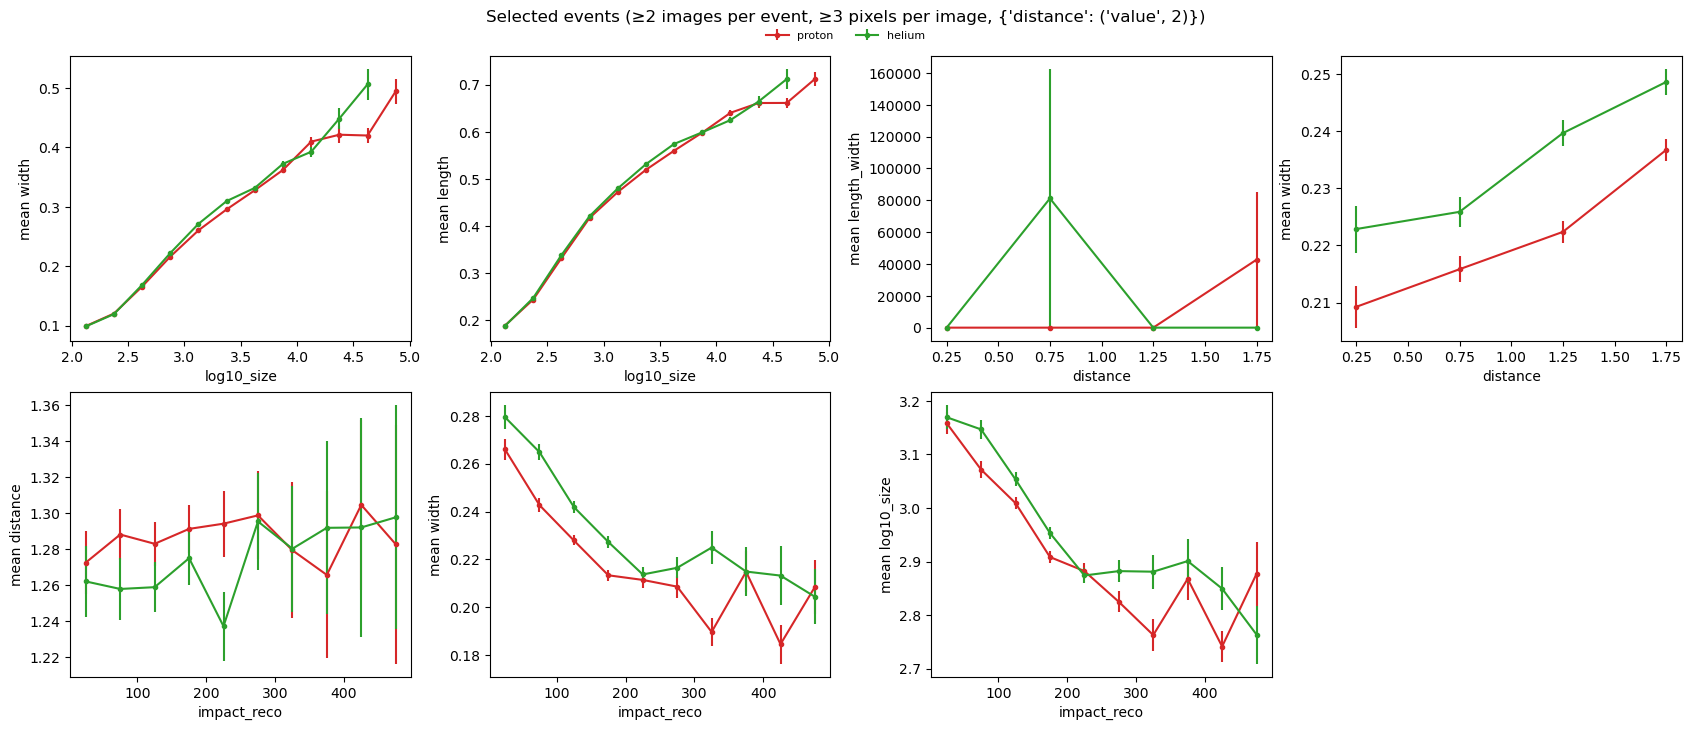

In [13]:
PROFILES = [ # (x, y, x bin edges): mean y in bins of x
    ("log10_size", "width", np.linspace(1.5, 5, 15)),
    ("log10_size", "length", np.linspace(1.5, 5, 15)),
    ("distance", "length_width", np.linspace(0, 5, 11)),
    ("distance", "width", np.linspace(0, 5, 11)),
    ("impact_reco", "distance", np.linspace(0, 500, 11)),
    ("impact_reco", "width", np.linspace(0, 500, 11)),
    ("impact_reco", "log10_size", np.linspace(0, 500, 11)),
]
plot_profiles(arrays, PROFILES, f"Selected events ({SELECTED})")

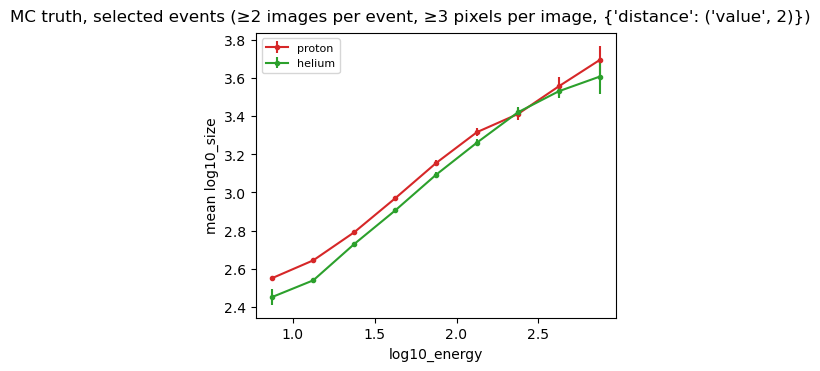

In [14]:
plot_profiles(arrays, [("log10_energy", "log10_size", np.linspace(0.5, 3, 11))], f"MC truth, selected events ({SELECTED})", n_cols=1)

# Reconstruction
Each event's `event_parameters()`, its arrival direction (`heap.reconstruction`) and its θ² to (`SOURCE_X`, `SOURCE_Y`). Each event's mean reconstructed impact distance (`mean_impact_reco`), and
`core_error`, the distance from the true core in the plane perpendicular to the pointing (`heap.process_simulation.tilted_core()`).

In [15]:
def event_parameters(array):
    """
    one row per event: n_images, log10_total_size (of its images' summed size), log10_SizeSecondMax (of its second
    largest image), max_distance (of its farthest image) and weight
    """
    grouped = array.groupby("Event")
    return pd.DataFrame({
        "n_images": grouped.size(),
        "log10_total_size": np.log10(grouped["size"].sum()),
        "log10_SizeSecondMax": np.log10(grouped["size"].apply(lambda size: size.nlargest(2).iloc[-1])),
        "max_distance": grouped.distance.max(),
        "weight": grouped.weight.first(),
    })

In [16]:
events = {}
for label, array in arrays.items():
    e = event_parameters(array).join(showers[label].set_index("Event")[["energy"]])
    e["log10_energy"] = np.log10(e.energy)
    e = e.join(reconstruct_directions(array).set_index("Event")[["Xoffset", "Yoffset"]])
    e["theta2"] = (e.Xoffset - SOURCE_X)**2 + (e.Yoffset - SOURCE_Y)**2
    e = e.join(cores[label].set_index("Event")).join(array.groupby("Event").impact_reco.mean().rename("mean_impact_reco"))
    true_x, true_y = ps.tilted_core(showers[label].set_index("Event").loc[e.index], runs[label].alt.mean(), runs[label].az.mean())
    e["core_error"] = np.hypot(e.core_x - true_x, e.core_y - true_y)
    events[label] = e
    print(f"{label}: {len(e)} events, {e.theta2.notna().sum()} directions and {e.core_x.notna().sum()} cores reconstructed, "
          f"core error median {e.core_error.median():.0f} m")

proton: 3151 events, 3151 directions and 3151 cores reconstructed, core error median 76 m
helium: 2478 events, 2478 directions and 2477 cores reconstructed, core error median 74 m


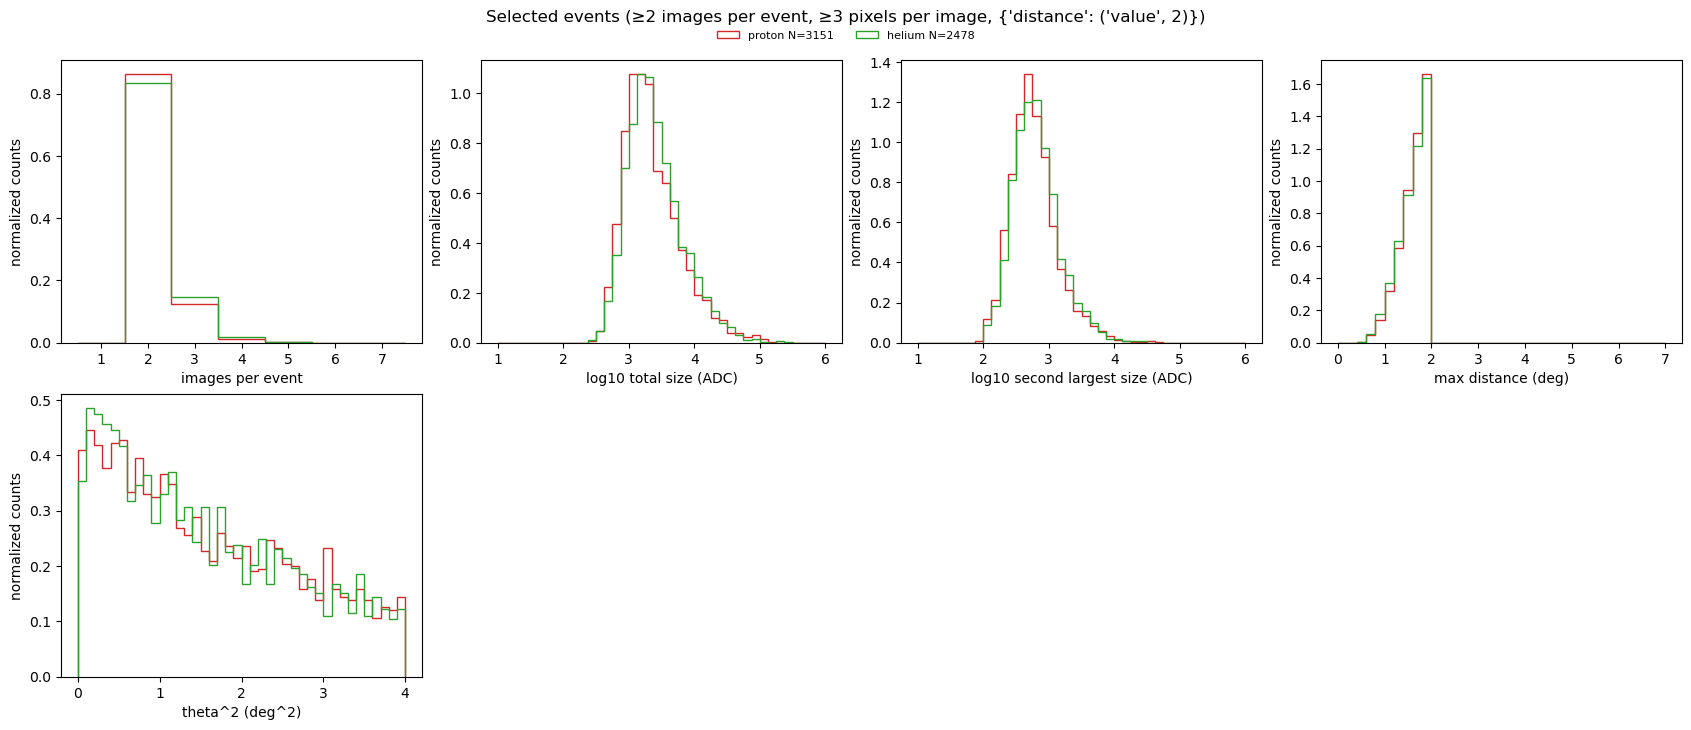

In [17]:
plot_hists(events, EVENT_PARAMS, f"Selected events ({SELECTED})")

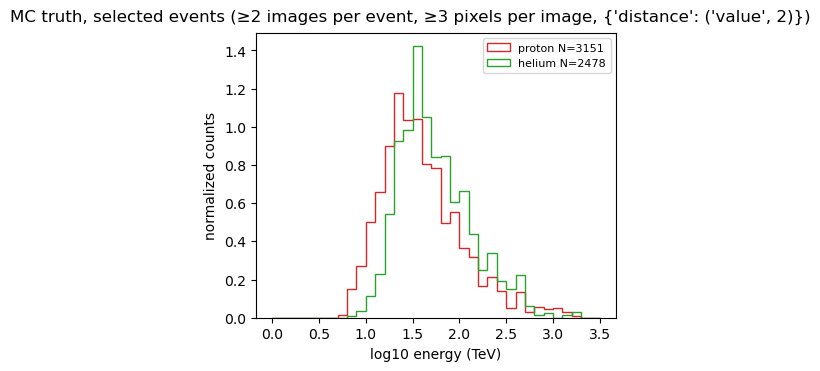

In [18]:
plot_hists(events, {"log10_energy": ("log10 energy (TeV)", np.linspace(0, 3.5, 36))}, f"MC truth, selected events ({SELECTED})", n_cols=1)

## Cores
Each image's reconstructed against true impact distance, and the core error's 68% containment per bin of true energy.
Near-parallel image axes (mostly two-image events) put a few cores kilometres away.

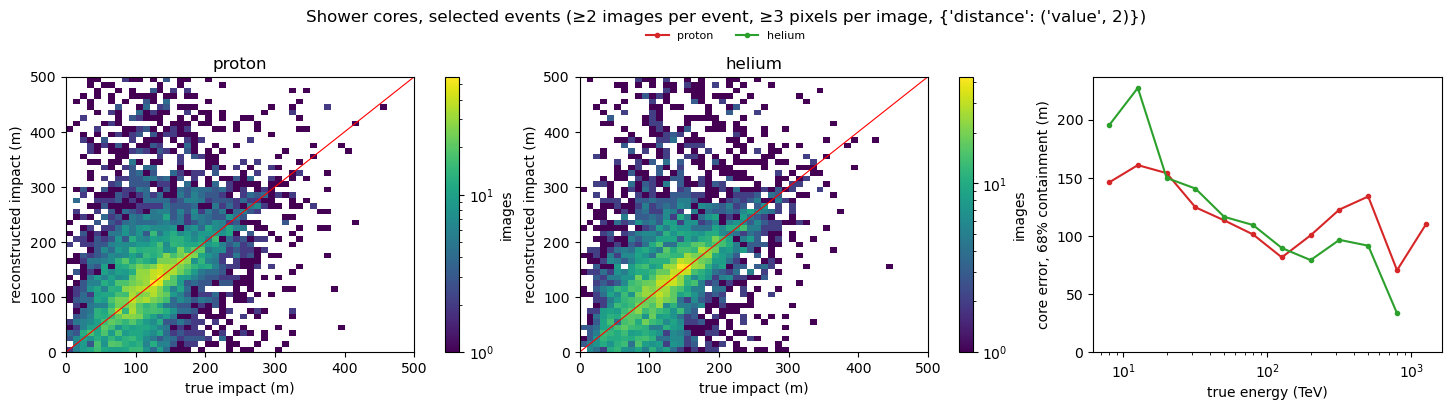

In [19]:
fig, axs = plt.subplots(1, len(arrays) + 1, figsize=(4.8*(len(arrays) + 1), 4), squeeze=False, layout="constrained")
impact_bins = np.linspace(0, 500, 51)
for ax, (label, array) in zip(axs[0], arrays.items()):
    *_, im = ax.hist2d(array.impact, array.impact_reco, bins=impact_bins, norm=LogNorm())
    fig.colorbar(im, ax=ax, label="images")
    ax.plot(impact_bins[[0, -1]], impact_bins[[0, -1]], "r-", lw=0.8)
    ax.set(xlabel="true impact (m)", ylabel="reconstructed impact (m)", title=label)
ax = axs[0, -1]
centers = np.sqrt(ENERGY_BINS[1:] * ENERGY_BINS[:-1])
for label, e in events.items():
    grouped = e.core_error.groupby(pd.cut(e.energy, ENERGY_BINS), observed=False)
    containment = grouped.quantile(0.68).where(grouped.size() >= 10)
    ax.plot(centers, containment.to_numpy(), "o-", ms=3, color=COLORS[label], label=label)
ax.set(xscale="log", ylim=(0, None), xlabel="true energy (TeV)", ylabel="core error, 68% containment (m)")
legend_and_title(fig, ax, axs.size, f"Shower cores, selected events ({SELECTED})")
plt.show()

# Random events
`N_EVENTS` random selected events of each production: each image, then every image's Hillas ellipse on one camera plane,
with the reconstructed direction (`heap.reconstruction.reconstruct_directions()`) and the true direction. Rerun for others.

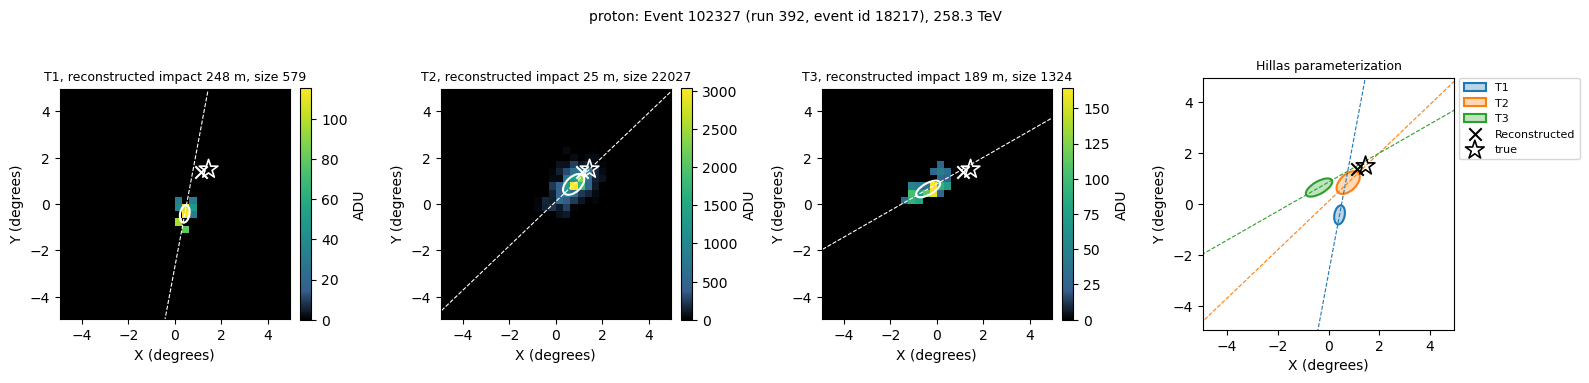

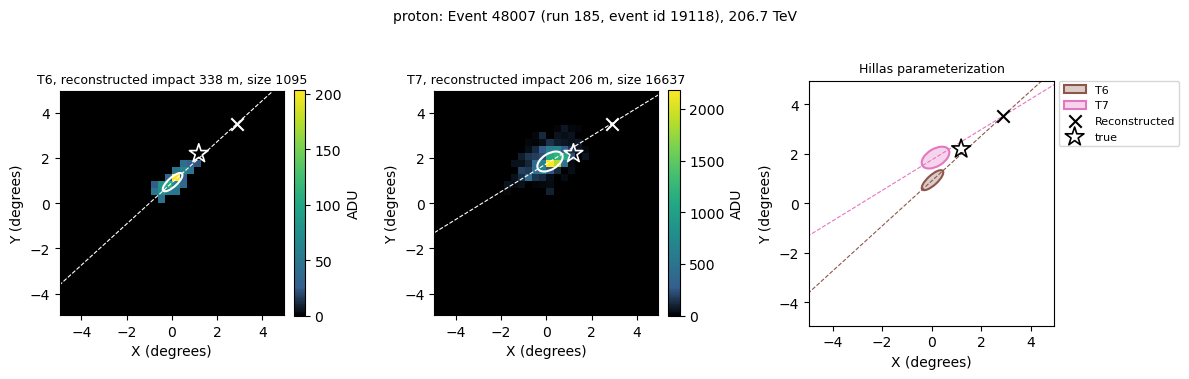

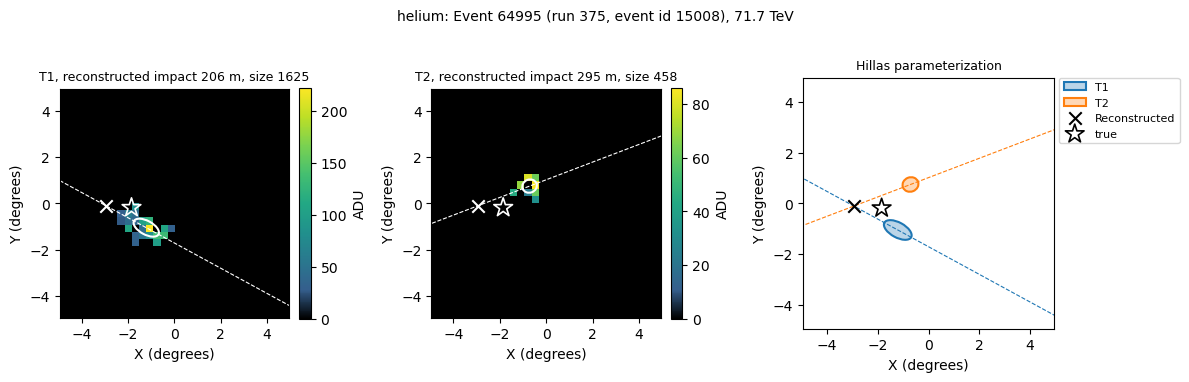

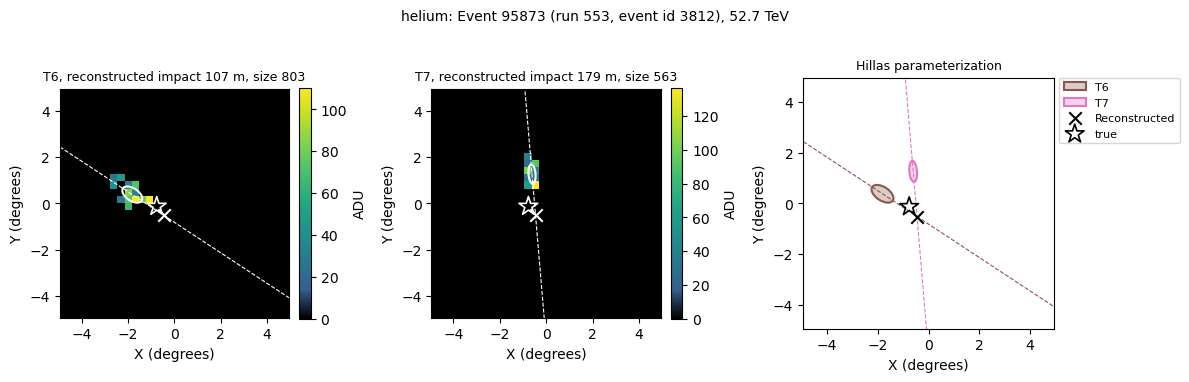

In [20]:
N_EVENTS = 2 # per production
TEL_COLORS = {name: f"C{i}" for i, name in enumerate(TELESCOPES)} # each telescope's ellipse in the combined panel

rng = np.random.default_rng()
for label, array in arrays.items():
    for e in rng.choice(array.Event.unique(), size=min(N_EVENTS, array.Event.nunique()), replace=False):
        event = array[array.Event == e]
        fig = ps.plot_event(
            event, reconstruct_directions(event).iloc[0], showers[label].set_index("Event").loc[e],
            ps.processed_path(SAMPLES[label]), SAMPLES[label]["production"]["name"], colors=TEL_COLORS,
        )
        fig.suptitle(f"{label}: {fig.get_suptitle()}", fontsize=10)
        plt.show()